# Clase 4 — Trama LoRa en el receptor: caso ideal y ruido

Construimos la secuencia acordada en clase: **8 upchirps completos**, **2 downchirps completos más 1/4 de otro downchirp**, y **un símbolo de 8 bits que representa un carácter ASCII**. Primero estudiamos el canal ideal y después agregamos ruido para evaluar la detección y la recuperación del payload.

Seguimos las ecuaciones (2) y (3) de Vangelista, *Frequency Shift Chirp Modulation: The LoRa Modulation* (sección II). Allí **un chirp completo dura `N = 2**SF` muestras**. Construimos los chirps de preámbulo y sincronización directamente con esa fórmula; `modular_simbolo` de `src.lora_chirp` se usa para el payload. Esta trama didáctica aún no incluye palabra de sincronización, codificación, encabezado ni CRC.

In [9]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import (
    agregar_ruido_awgn, demodular_simbolo, modular_simbolo,
    parametros_ruido_desde_snr, validar_simbolos,
)

## 1. Parámetros y byte ASCII

Según el artículo, $T=1/B$, $N=2^{SF}$ y $T_s=N/B$. La forma de onda completa se define para $k=0,1,…,N-1$ como $c_s[k]=N^{-1/2}e^{j2π[((s+k) mod N)k/N]}$. Con `SF = 8` y $B=125$ kHz, **cada chirp tiene 256 muestras y dura 2,048 ms**. Elegimos `A`, cuyo código ASCII es 65 (`01000001`).

In [10]:
B = 125_000  # Hz; también es la frecuencia de muestreo de este modelo
caracter = 'A'  # cambiar por otro carácter ASCII si se desea
assert len(caracter) == 1 and ord(caracter) < 128, 'Elegí un único carácter ASCII'
valor_ascii = ord(caracter)
bits_payload = f'{valor_ascii:08b}'
SF = validar_simbolos([bits_payload])
N = 2**SF
Ts = N / B
k = np.arange(N)

print(f'Carácter: {caracter!r} | ASCII: {valor_ascii} | bits: {bits_payload}')
print(f'SF={SF} | chirp={N} muestras | Ts={Ts * 1e3:.3f} ms')

Carácter: 'A' | ASCII: 65 | bits: 01000001
SF=8 | chirp=256 muestras | Ts=2.048 ms


## 2. Construcción de la señal recibida ideal

Para $s=0$, la ecuación (3) se reduce a $c_0[k]=N^{-1/2}e^{j2πk^2/N}$, con **`N` muestras por chirp**. Repetimos ese upchirp ocho veces; el downchirp es su conjugado y agregamos dos copias completas más las primeras `N/4` muestras de una tercera. El cuarto de downchirp dura **0,512 ms**. El payload es un chirp completo modulado con el valor ASCII.

In [11]:
upchirp_cero = np.exp(1j * 2 * np.pi * k**2 / N) / np.sqrt(N)
downchirp_cero = np.conj(upchirp_cero)
simbolo_payload = modular_simbolo(valor_ascii, k, N)

preambulo = np.tile(upchirp_cero, 8)
sincronizacion = np.concatenate((downchirp_cero, downchirp_cero, downchirp_cero[:N // 4]))
trama_transmitida = np.concatenate((preambulo, sincronizacion, simbolo_payload))
recibida_ideal = trama_transmitida.copy()  # canal ideal: r[k] = x[k]

limites = np.array([0, 8*N, 10*N, 10*N + N//4, 11*N + N//4])
assert len(recibida_ideal) == limites[-1] == 2880
np.testing.assert_array_equal(preambulo.reshape(8, N), np.tile(upchirp_cero, (8, 1)))
np.testing.assert_array_equal(sincronizacion[:2*N].reshape(2, N),
                              np.tile(downchirp_cero, (2, 1)))
np.testing.assert_array_equal(sincronizacion[2*N:], downchirp_cero[:N//4])
np.testing.assert_array_equal(recibida_ideal[-N:], simbolo_payload)

print(f'Preámbulo: {len(preambulo)} muestras (8 chirps)')
print(f'Downchirps: {len(sincronizacion)} muestras (2,25 chirps)')
print(f'Payload: {len(simbolo_payload)} muestras (1 chirp de 8 bits)')
print(f'Trama recibida ideal: {len(recibida_ideal)} muestras, {len(recibida_ideal)/B * 1e3:.3f} ms')

Preámbulo: 2048 muestras (8 chirps)
Downchirps: 576 muestras (2,25 chirps)
Payload: 256 muestras (1 chirp de 8 bits)
Trama recibida ideal: 2880 muestras, 23.040 ms


## 3. Aspecto de la trama completa

Arriba se ve la parte real de las muestras complejas recibidas. Abajo se grafica el **índice modular** $[(s+k) mod N]B/N$ de la ecuación (3), con ocho rampas ascendentes, dos descendentes y un cuarto de descendente. El payload empieza desplazado por su valor 65. Las líneas punteadas separan los chirps completos.

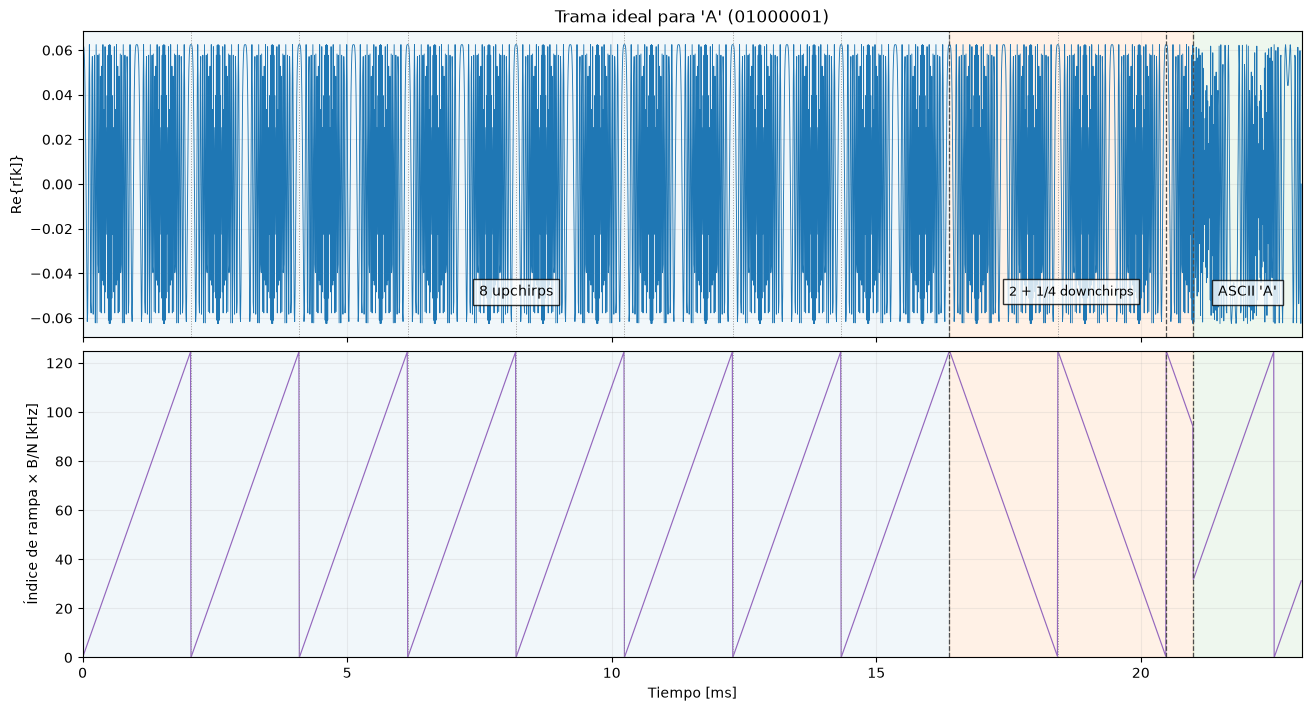

In [12]:
# Índice (s+k) mod N de la ecuación (3), expresado sobre la banda B.
rampa_up = k * B / N
rampa_down = B - rampa_up  # B y 0 son el mismo borde en frecuencia discreta
rampa_payload = np.mod(valor_ascii + k, N) * B / N
rampa_trama = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                              rampa_down[:N//4], rampa_payload))
assert len(rampa_trama) == len(recibida_ideal)
tiempo_ms = np.arange(len(recibida_ideal)) / B * 1e3

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
axes[0].plot(tiempo_ms, recibida_ideal.real, lw=0.65, color='tab:blue')
axes[0].set(ylabel='Re{r[k]}', title=f'Trama ideal para {caracter!r} ({bits_payload})')
axes[1].plot(tiempo_ms, rampa_trama / 1e3, lw=0.85, color='tab:purple')
axes[1].set(xlabel='Tiempo [ms]', ylabel='Índice de rampa × B/N [kHz]')

for ax in axes:
    ax.axvspan(0, limites[1]/B*1e3, color='tab:blue', alpha=0.06)
    ax.axvspan(limites[1]/B*1e3, limites[3]/B*1e3, color='tab:orange', alpha=0.10)
    ax.axvspan(limites[3]/B*1e3, limites[4]/B*1e3, color='tab:green', alpha=0.08)
    for muestra in np.arange(N, 10*N, N):
        ax.axvline(muestra/B*1e3, color='0.6', ls=':', lw=0.7)
    for muestra in limites[1:-1]:
        ax.axvline(muestra/B*1e3, color='0.3', ls='--', lw=0.9)
    ax.grid(True, alpha=0.2)

axes[0].text(limites[1]/(2*B)*1e3, -0.05, '8 upchirps', ha='center', bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[1]+limites[3])/(2*B)*1e3, -0.05, '2 + 1/4 downchirps', ha='center', fontsize=9, bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[3]+limites[4])/(2*B)*1e3, -0.05, f'ASCII {caracter!r}', ha='center', bbox={'facecolor': 'white', 'alpha': 0.8})
axes[1].set_ylim(0, B/1e3)
axes[1].set_xlim(0, len(recibida_ideal)/B*1e3)
plt.show()

## 4. Detector de trama

El detector no recibe la trama ya recortada: recibe un **bloque de muestras** y debe responder si la trama está presente y en qué muestra comienza. Para este experimento sin ruido agregamos cantidades **aleatorias e impares** de ceros antes y después. Así el comienzo no necesita estar alineado con `N`. Conocemos el inicio verdadero sólo porque construimos la señal; el detector no lo usará para decidir.

En el modelo del artículo, cada chirp completo sigue teniendo `N=2**SF` muestras. Los ceros son márgenes de observación, no símbolos LoRa.


In [13]:
generador_margenes = np.random.default_rng()  # nuevas longitudes al volver a ejecutar
muestras_antes = int(2 * generador_margenes.integers(0, N) + 1)  # impar: no múltiplo de N
muestras_despues = int(2 * generador_margenes.integers(0, N) + 1)
margen_antes = np.zeros(muestras_antes, dtype=complex)
margen_despues = np.zeros(muestras_despues, dtype=complex)
bloque_recibido = np.concatenate((margen_antes, recibida_ideal, margen_despues))
inicio_verdadero = len(margen_antes)  # sólo para verificar el experimento
fin_verdadero = inicio_verdadero + len(recibida_ideal)

print(f'Reposo: {muestras_antes} muestras antes y {muestras_despues} después')
print(f'Bloque observado: {len(bloque_recibido)} muestras')
print(f'Inicio verdadero: muestra {inicio_verdadero} = {inicio_verdadero/B*1e3:.3f} ms')
print(f'Fin verdadero (exclusivo): muestra {fin_verdadero}')


Reposo: 359 muestras antes y 89 después
Bloque observado: 3328 muestras
Inicio verdadero: muestra 359 = 2.872 ms
Fin verdadero (exclusivo): muestra 3239


**Nota sobre la energía.** En el caso ideal, el reposo es exactamente cero y permitiría ubicar el comienzo de la actividad. Con ruido también hay energía fuera de la trama. En este notebook usaremos la correlación con la cabecera conocida para detectar el inicio.


## 4.1. Detección temporal: correlación con la cabecera

La **plantilla** contiene sólo las partes que el receptor conoce de antemano: los 8 upchirps del preámbulo, los 2 downchirps y el último cuarto de downchirp. El payload ASCII no participa, porque todavía es desconocido para el receptor.

Deslizamos la plantilla sobre el bloque. Para cada inicio candidato $m$, comparamos la ventana $r[m:m+L]$ con la plantilla $h$ usando

$$
C[m]=\frac{|\langle h,r[m:m+L]\rangle|^2}
{\|h\|^2\,\|r[m:m+L]\|^2}.
$$

La correlación compleja se calcula con `np.vdot(h, ventana)`, que conjuga la plantilla. El puntaje vale **1** cuando ambas formas coinciden salvo por una ganancia/fase compleja común, y **0** en una ventana sin energía. Un pico aislado con sólo el preámbulo puede ser ambiguo por la repetición de chirps; agregar los downchirps a la plantilla confirma también la transición de sincronización.

El umbral cercano a 1 de abajo es **exclusivo de esta prueba ideal sin ruido**. Con ruido habrá que elegirlo y validarlo de otra manera.

**Para más adelante.** Al agregar ruido, el máximo de correlación ya no será necesariamente cercano a 1. La calibración del umbral con bloques de ruido solo y el estudio de falsas alarmas quedan como una ampliación posterior.


In [14]:
def puntajes_correlacion(bloque, plantilla):
    """Correlación normalizada para todos los inicios posibles."""
    if len(bloque) < len(plantilla):
        raise ValueError('El bloque debe contener al menos una plantilla completa')
    energia_plantilla = np.vdot(plantilla, plantilla).real
    puntajes = np.zeros(len(bloque) - len(plantilla) + 1)

    for m in range(len(puntajes)):
        ventana = bloque[m:m + len(plantilla)]
        energia_ventana = np.vdot(ventana, ventana).real
        if energia_ventana > 0:  # evita dividir por cero en el reposo
            coincidencia = np.vdot(plantilla, ventana)
            puntajes[m] = abs(coincidencia) ** 2 / (energia_plantilla * energia_ventana)
    return puntajes


cabecera_conocida = np.concatenate((preambulo, sincronizacion))
puntajes_preambulo = puntajes_correlacion(bloque_recibido, preambulo)
puntajes_cabecera = puntajes_correlacion(bloque_recibido, cabecera_conocida)

mejor_inicio = int(np.argmax(puntajes_cabecera))
mejor_puntaje = puntajes_cabecera[mejor_inicio]
umbral_ideal = 1 - 1e-10  # coincidencia casi perfecta; NO es un umbral para ruido
existe_trama = bool(mejor_puntaje >= umbral_ideal)
inicio_detectado = mejor_inicio if existe_trama else None

# Caso de control: un bloque del mismo tamaño pero sin ninguna trama.
bloque_sin_trama = np.zeros_like(bloque_recibido)
puntajes_sin_trama = puntajes_correlacion(bloque_sin_trama, cabecera_conocida)
existe_en_control = bool(np.max(puntajes_sin_trama) >= umbral_ideal)

assert existe_trama and inicio_detectado == inicio_verdadero
assert not existe_en_control
print(f'Bloque con trama: ¿existe? {existe_trama}; inicio = {inicio_detectado}; Cmáx = {mejor_puntaje:.12f}')
print(f'Bloque vacío: ¿existe? {existe_en_control}; Cmáx = {np.max(puntajes_sin_trama):.12f}')


Bloque con trama: ¿existe? True; inicio = 359; Cmáx = 1.000000000000
Bloque vacío: ¿existe? False; Cmáx = 0.000000000000


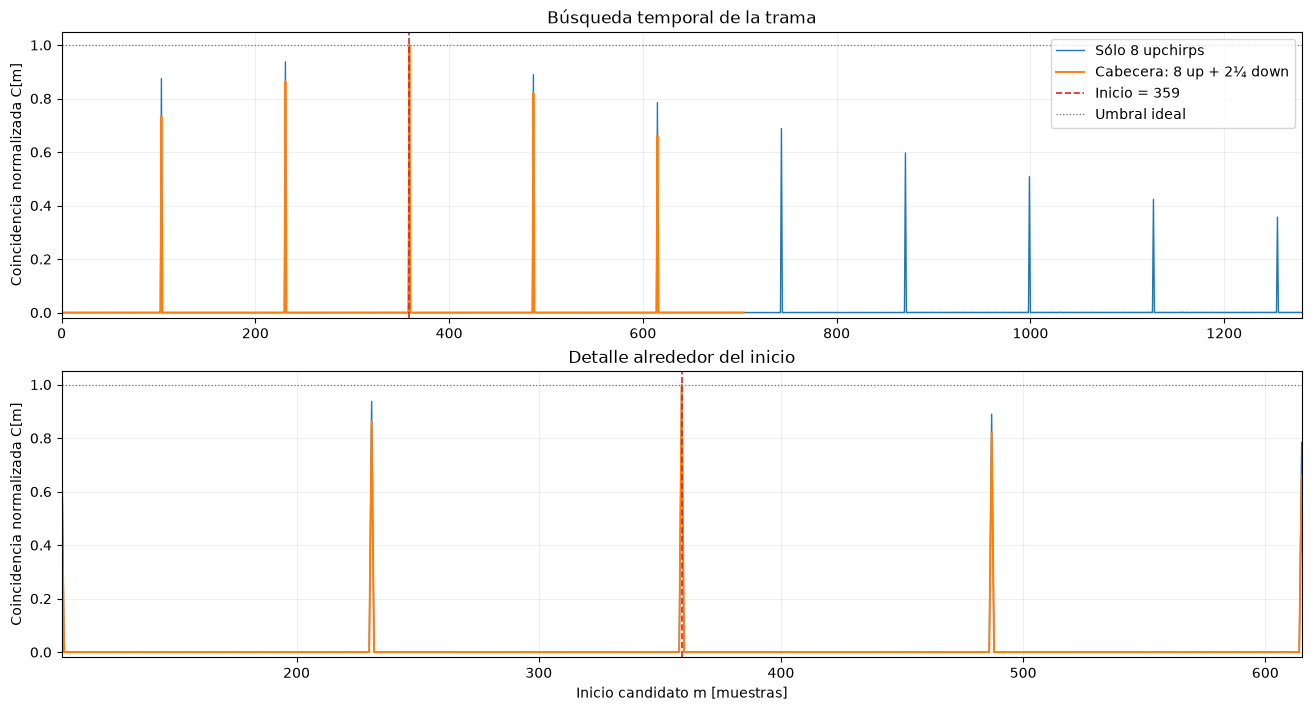

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharey=True, constrained_layout=True)
for ax in axes:
    ax.plot(np.arange(len(puntajes_preambulo)), puntajes_preambulo,
            lw=1, color='tab:blue', label='Sólo 8 upchirps')
    ax.plot(np.arange(len(puntajes_cabecera)), puntajes_cabecera,
            lw=1.4, color='tab:orange', label='Cabecera: 8 up + 2¼ down')
    ax.axvline(inicio_detectado, color='tab:red', ls='--', lw=1.2,
               label=f'Inicio = {inicio_detectado}')
    ax.axhline(umbral_ideal, color='0.45', ls=':', lw=0.9, label='Umbral ideal')
    ax.set(ylabel='Coincidencia normalizada C[m]', ylim=(-0.02, 1.05))
    ax.grid(True, alpha=0.2)

axes[0].set(title='Búsqueda temporal de la trama', xlim=(0, len(puntajes_preambulo) - 1))
axes[0].legend(loc='upper right')
axes[1].set(xlabel='Inicio candidato m [muestras]',
            xlim=(max(0, inicio_detectado - N), inicio_detectado + N),
            title='Detalle alrededor del inicio')
plt.show()


**Lectura de los resultados.** La correlación con la cabecera busca si está presente la secuencia conocida y en qué muestra comienza. En esta prueba ideal, el inicio detectado debe coincidir con la longitud del margen anterior, aunque no sea múltiplo de `N`.

Los picos secundarios del preámbulo aparecen separados por `N/2` muestras: con la fórmula discreta de Vangelista que usamos en esta clase, el upchirp de valor cero repite su mitad. Cada símbolo construido sigue teniendo `N` muestras; en este experimento la cabecera completa sólo alcanza coincidencia 1 en el inicio correcto.

Con ese inicio detectado, ahora podemos ubicar y recuperar el payload. La detección del preámbulo por frecuencia queda para otra exploración.


## 5. Recuperar el payload sin ruido

El payload empieza en `inicio_detectado + len(cabecera_conocida)`. Recortamos las siguientes `N` muestras del bloque recibido y usamos `demodular_simbolo` (dechirp + FFT) para recuperar el valor, los bits y el carácter. Para `A` esperamos `65 → 01000001`.


In [16]:
if inicio_detectado is None:
    raise ValueError('No se detectó una cabecera; no se puede ubicar el payload')

inicio_payload = inicio_detectado + len(cabecera_conocida)
fin_payload = inicio_payload + N  # índice final exclusivo
payload_recibido = bloque_recibido[inicio_payload:fin_payload]
if len(payload_recibido) != N:
    raise ValueError('El bloque recibido no contiene el payload completo')

valor_recuperado, _, _ = demodular_simbolo(payload_recibido)
bits_recuperados = f'{valor_recuperado:0{SF}b}'
caracter_recuperado = chr(valor_recuperado)

print(f'Inicio detectado de la trama: {inicio_detectado}')
print(f'Cabecera conocida: {len(cabecera_conocida)} muestras')
print(f'Payload: muestras [{inicio_payload}:{fin_payload}) ({len(payload_recibido)} muestras)')
print(f'Símbolo recuperado: {valor_recuperado}')
print(f'Bits recuperados: {bits_recuperados}')
print(f'Carácter recuperado: {caracter_recuperado!r}')

assert valor_recuperado == valor_ascii, 'El símbolo recuperado no coincide con el transmitido'
assert bits_recuperados == bits_payload
print('Verificación sin ruido: payload recuperado correctamente')


Inicio detectado de la trama: 359
Cabecera conocida: 2624 muestras
Payload: muestras [2983:3239) (256 muestras)
Símbolo recuperado: 65
Bits recuperados: 01000001
Carácter recuperado: 'A'
Verificación sin ruido: payload recuperado correctamente


## 6. Detección y payload con ruido

Agregamos ruido gaussiano blanco complejo a **todo** el bloque: $r[n]=x[n]+w[n]$. Fuera de la trama queda ruido solo; dentro, señal más ruido. La SNR se calcula con la potencia de la **trama activa**, sin incluir los ceros.

Usamos la misma correlación. Como con ruido el puntaje baja, elegimos un **umbral manual** `umbral_ruido = 0.01`: si el máximo no lo supera, declaramos que no detectamos trama. Es un valor didáctico modificable; su calibración y las falsas alarmas quedan para más adelante.


In [17]:
umbral_ruido = 0.01  # manual, no calibrado; cambiarlo afecta el resultado
potencia_trama = np.mean(np.abs(trama_transmitida) ** 2)


def detectar_payload(bloque, umbral):
    """Busca la cabecera y lee el símbolo a partir del inicio estimado."""
    puntajes = puntajes_correlacion(bloque, cabecera_conocida)
    candidato = int(np.argmax(puntajes))
    if puntajes[candidato] <= umbral:
        return None, None, puntajes

    inicio_dato = candidato + len(cabecera_conocida)
    muestras_dato = bloque[inicio_dato:inicio_dato + N]
    valor = demodular_simbolo(muestras_dato)[0] if len(muestras_dato) == N else None
    return candidato, valor, puntajes


SNR objetivo: -7 dB | potencia de ruido: 0.019578
Cmáx sin ruido: 1.0000 | con ruido: 0.1549
Inicio verdadero: 359 | detectado con ruido: 359
Símbolo transmitido: 65 | recuperado: 65
¿Paquete correcto?: True


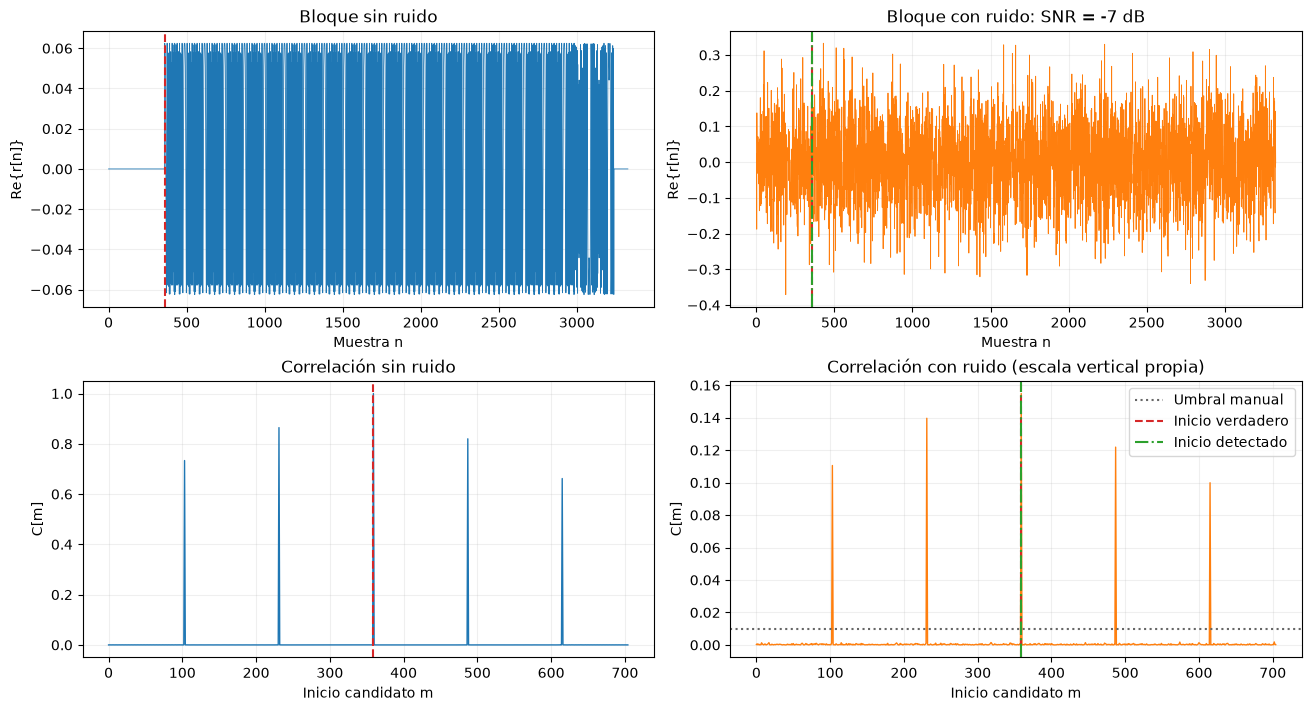

In [21]:
snr_ejemplo_db = -7  # volver a ejecutar con otra SNR para comparar
generador_ruido = np.random.default_rng(2026)
potencia_ruido, sigma = parametros_ruido_desde_snr(snr_ejemplo_db, potencia_trama)
bloque_con_ruido, ruido = agregar_ruido_awgn(bloque_recibido, sigma, generador_ruido)

inicio_con_ruido, valor_con_ruido, puntajes_con_ruido = detectar_payload(
    bloque_con_ruido, umbral_ruido)
paquete_correcto = (inicio_con_ruido == inicio_verdadero and valor_con_ruido == valor_ascii)

print(f'SNR objetivo: {snr_ejemplo_db} dB | potencia de ruido: {potencia_ruido:.6f}')
print(f'Cmáx sin ruido: {mejor_puntaje:.4f} | con ruido: {puntajes_con_ruido.max():.4f}')
print(f'Inicio verdadero: {inicio_verdadero} | detectado con ruido: {inicio_con_ruido}')
print(f'Símbolo transmitido: {valor_ascii} | recuperado: {valor_con_ruido}')
print(f'¿Paquete correcto?: {paquete_correcto}')

fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
axes[0, 0].plot(bloque_recibido.real, lw=0.6)
axes[0, 0].set(title='Bloque sin ruido', ylabel='Re{r[n]}', xlabel='Muestra n')
axes[0, 1].plot(bloque_con_ruido.real, lw=0.6, color='tab:orange')
axes[0, 1].set(title=f'Bloque con ruido: SNR = {snr_ejemplo_db} dB',
               ylabel='Re{r[n]}', xlabel='Muestra n')
axes[1, 0].plot(puntajes_cabecera, lw=1)
axes[1, 0].set(title='Correlación sin ruido', ylabel='C[m]', xlabel='Inicio candidato m')
axes[1, 1].plot(puntajes_con_ruido, lw=1, color='tab:orange')
axes[1, 1].axhline(umbral_ruido, color='0.4', ls=':', label='Umbral manual')
axes[1, 1].set(title='Correlación con ruido (escala vertical propia)',
               ylabel='C[m]', xlabel='Inicio candidato m')
for ax in axes.flat:
    ax.axvline(inicio_verdadero, color='tab:red', ls='--', label='Inicio verdadero')
    ax.grid(True, alpha=0.2)
if inicio_con_ruido is not None:
    for ax in axes[:, 1]:
        ax.axvline(inicio_con_ruido, color='tab:green', ls='-.', label='Inicio detectado')
axes[1, 1].legend()
plt.show()


## 7. Packet error rate (PER) frente a SNR

Repetimos el experimento con ruido e inicios aleatorios. Un paquete falla si **no se detecta**, **se ubica mal** o **se recupera mal el payload**. Cada paquete fallido cuenta una sola vez:

$$\mathrm{PER}=\frac{\text{paquetes fallidos}}{\text{paquetes transmitidos}}.$$

Todos los ensayos usan el mismo payload y bloques de igual longitud. Exigimos inicio exacto porque este modelo tiene desplazamientos enteros de muestra. El inicio verdadero se usa sólo para evaluar y para una curva de referencia: **leer el dato suponiendo que ya conocemos el inicio**. Las dos curvas usan el mismo ruido en cada ensayo.

`paquetes_por_snr` controla el tiempo y la precisión del experimento. Una PER observada de cero significa que no hubo errores en esos ensayos; no garantiza que la probabilidad real sea cero.


In [19]:
snrs_db = np.array([-30, -25, -20, -18, -15, -12, -10, -5, 0])
paquetes_por_snr = 1000
generador_per = np.random.default_rng(2027)
resultados_per = []

print(' SNR   No detecta  Inicio mal  Dato mal  Errores/total    PER  PER inicio conocido')
for snr_db in snrs_db:
    _, sigma_per = parametros_ruido_desde_snr(snr_db, potencia_trama)
    no_detectados = inicios_erroneos = datos_erroneos = errores_referencia = 0

    for _ in range(paquetes_por_snr):
        inicio_real = int(2 * generador_per.integers(0, N) + 1)
        bloque_limpio = np.concatenate((
            np.zeros(inicio_real, dtype=complex), trama_transmitida,
            np.zeros(2 * N - inicio_real, dtype=complex)))
        recibido, _ = agregar_ruido_awgn(bloque_limpio, sigma_per, generador_per)
        inicio_estimado, dato_estimado, _ = detectar_payload(recibido, umbral_ruido)

        # Clasificación excluyente: cada paquete fallido se cuenta una sola vez.
        if inicio_estimado is None:
            no_detectados += 1
        elif inicio_estimado != inicio_real:
            inicios_erroneos += 1
        elif dato_estimado != valor_ascii:
            datos_erroneos += 1

        # Referencia con sincronización conocida; no interviene en el detector.
        inicio_dato_real = inicio_real + len(cabecera_conocida)
        dato_referencia = demodular_simbolo(recibido[inicio_dato_real:inicio_dato_real + N])[0]
        errores_referencia += int(dato_referencia != valor_ascii)

    errores = no_detectados + inicios_erroneos + datos_erroneos
    per = errores / paquetes_por_snr
    per_referencia = errores_referencia / paquetes_por_snr
    tasa_fallo_inicio = (no_detectados + inicios_erroneos) / paquetes_por_snr
    resultados_per.append((snr_db, per, per_referencia, tasa_fallo_inicio))
    assert 0 <= per_referencia <= per <= 1
    print(f'{snr_db:4.0f} {no_detectados:11d} {inicios_erroneos:11d} {datos_erroneos:9d}'
          f' {errores:5d}/{paquetes_por_snr:<5d} {per:7.3f} {per_referencia:20.3f}')


 SNR   No detecta  Inicio mal  Dato mal  Errores/total    PER  PER inicio conocido
 -30        1000           0         0  1000/1000    1.000                0.996
 -25         998           0         2  1000/1000    1.000                0.970
 -20         486          38       410   934/1000    0.934                0.848
 -18          25          46       622   693/1000    0.693                0.660
 -15           0           6       231   237/1000    0.237                0.232
 -12           0           0        17    17/1000    0.017                0.017
 -10           0           0         0     0/1000    0.000                0.000
  -5           0           0         0     0/1000    0.000                0.000
   0           0           0         0     0/1000    0.000                0.000


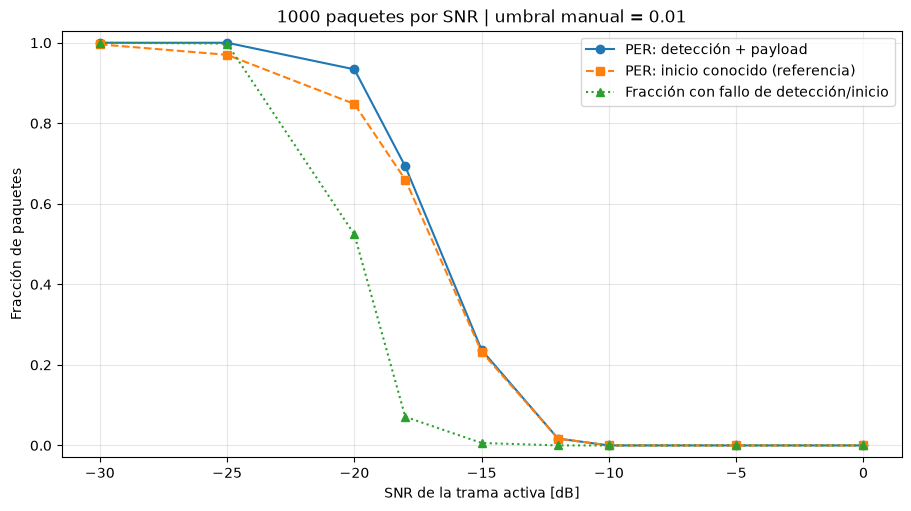

In [20]:
resultados_per = np.asarray(resultados_per)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.plot(resultados_per[:, 0], resultados_per[:, 1], 'o-', label='PER: detección + payload')
ax.plot(resultados_per[:, 0], resultados_per[:, 2], 's--', label='PER: inicio conocido (referencia)')
ax.plot(resultados_per[:, 0], resultados_per[:, 3], '^:', label='Fracción con fallo de detección/inicio')
ax.set(xlabel='SNR de la trama activa [dB]', ylabel='Fracción de paquetes',
       title=f'{paquetes_por_snr} paquetes por SNR | umbral manual = {umbral_ruido}',
       ylim=(-0.03, 1.03))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


La curva de **inicio conocido** muestra los errores al leer sólo el dato. La PER completa suma los fallos al detectar y ubicar la trama. Cambiar `umbral_ruido` permite observar cómo cambia esa diferencia. Sin ruido, la sección 5 recupera el paquete correctamente.

Estos resultados corresponden al modelo de Vangelista usado en clase, con AWGN y sin desajustes de frecuencia o de reloj. El umbral sigue siendo manual; todavía no medimos falsas alarmas.
